# Freight Capstone: Network + Base Selection + Temporal Validation
## เลือกฐานรับจ้างขนส่งภายใต้จำนวนฐานจำกัด
Notebook ภาษาไทย: ข้อมูล → เลือกสินค้า → Network → validation → Model A/B → ตรวจย้อนหลัง → กราฟและข้อสรุป

**สถานะ:** ผลเพื่อศึกษาความเป็นไปได้ ไม่ใช่คำแนะนำลงทุน ใช้ข้อมูลหลัก ม.ค.–เม.ย. 2569 เทียบปี 2568 เฉพาะเดือนร่วม

### วิธีใช้
1. แตก ZIP ที่ให้ไว้ แล้วเปิด notebook ในโฟลเดอร์เดียวกับ `data/` บน Jupyter
2. สำหรับ Colab ให้อัปโหลด ZIP จากเซลล์ตัวเลือกด้านล่าง แล้วรันทุกเซลล์ตามลำดับ
3. โหมดเต็มใช้ 100 seeds และ null 100 ครั้ง อาจใช้เวลาหลายนาที ผลที่คำนวณจะอยู่ `results/`

ตัวเลขไม่ถูกเขียนทับให้ตรงรายงานเดิม ถ้าข้อมูล/เวอร์ชันไลบรารีเปลี่ยน ผล partition และคำตอบที่คะแนนเสมอกันอาจเปลี่ยนได้ ให้ตรวจผลจริงก่อนนำไปใส่สไลด์

## เปิดจาก GitHub/Colab
เซลล์ถัดไปดาวน์โหลดข้อมูลดิบสองปีจาก สนข. (รวมประมาณ 133 MB) และไฟล์พิกัด/ระยะจาก repo โดยตรวจ hash กับชุดที่ใช้รัน ผลที่บันทึกไว้เป็นผลจากข้อมูลเดิม การดาวน์โหลดขึ้นกับบริการต้นทาง

เซลล์ bootstrap เพิ่มสำหรับ GitHub; ผลการวิเคราะห์ด้านล่างรันครบแล้วบนข้อมูลในเครื่อง ไม่ได้ยืนยันการดาวน์โหลดต้นทางบน Colab หาก source เปลี่ยนจะหยุดเพื่อไม่ใช้ข้อมูลต่างชุดโดยไม่รู้ตัว

In [ ]:
# GitHub / Colab bootstrap: official source CSVs + small reference files
from pathlib import Path
import urllib.request, hashlib, json
root_url = 'https://raw.githubusercontent.com/Pornphrom/MADT7202_capstone_freight/main/'
data = Path('data'); data.mkdir(exist_ok=True)
sources = {
 'otp_69_01_69.csv': 'https://otp.gdcatalog.go.th/dataset/91038df9-854e-442d-8408-c54032daf506/resource/ac3db7c7-c4f1-4ca8-93b9-62d36d832f97/download/otp_69_01_69.csv',
 'otp_69_01_68.csv': 'https://otp.gdcatalog.go.th/dataset/91038df9-854e-442d-8408-c54032daf506/resource/5f502b31-3c49-4faa-9a02-34a92abdb863/download/otp_69_01_68.csv',
 'province_coordinates_used.csv': root_url+'data/province_coordinates_used.csv',
 'straight_line_distance_km.csv': root_url+'data/straight_line_distance_km.csv',
}
expected = {'otp_69_01_68.csv': '86373d5a61b5ebc81ddaa547fa7bbdd8bb12253624c000a3d469b4ddc31aa3ca', 'otp_69_01_69.csv': 'ee38ebd5ef670489f321a93d2c32e94e1f7ed57d6e5e76a5bcb14fb72963bd82', 'province_coordinates_used.csv': '6082b1b14a740130455e75c3596358f62af6549b60d31a81b16c8a69bed68c48', 'straight_line_distance_km.csv': 'ce2f1e3e656f23435d6b2b5562909c9d2fe6ee49fca70325adf742d92019ced1'}
for name,url in sources.items():
    target=data/name
    if not target.exists():
        print('Downloading',name)
        partial=data/(name+'.part')
        urllib.request.urlretrieve(url,partial)
        partial.replace(target)
    actual=hashlib.sha256(target.read_bytes()).hexdigest()
    assert actual==expected[name], f'{name}: source differs from tested snapshot; use original data or investigate before rerunning'
print('All required input hashes verified')


In [1]:
# รันครั้งแรกใน Colab/Jupyter หากยังไม่มีไลบรารี (นำ # ออก)
# %pip install pandas numpy scipy networkx matplotlib
# สำหรับ Colab: อัปโหลด ZIP ที่ได้รับ แล้วแตกไฟล์
# from google.colab import files
# import zipfile
# uploaded = files.upload()
# for name in uploaded:
#     if name.endswith('.zip'):
#         with zipfile.ZipFile(name) as z: z.extractall('.')

In [2]:
from pathlib import Path
import json, hashlib, platform
import pandas as pd
import numpy as np
import networkx as nx
import scipy
from scipy.optimize import milp, Bounds, LinearConstraint
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('data')
O = Path('results'); O.mkdir(exist_ok=True)
SEEDS = 100
NULL_REPEATS = 100
NULL_SEEDS = 10
RADIUS_KM = 150
assert SEEDS >= NULL_SEEDS and NULL_REPEATS > 0
versions = {'python':platform.python_version(), 'pandas':pd.__version__, 'numpy':np.__version__, 'networkx':nx.__version__, 'scipy':scipy.__version__}
print(versions)
(O/'versions.json').write_text(json.dumps(versions,indent=2))

{'python': '3.12.14', 'pandas': '3.0.1', 'numpy': '2.5.4', 'networkx': '3.7', 'scipy': '1.18.1'}


108

## 1. ข้อมูลและการเลือกสินค้า
21 ประเภทในข้อมูลทั้งหมด → พอร์ตเกษตรและอาหารเริ่มต้น 8 ประเภท → กรณีหลักไม่รับอ้อยเหลือ 7 ประเภท

**ใช้:** ข้าวเปลือก ข้าว ข้าวโพด ผลิตภัณฑ์มันสำปะหลัง น้ำตาลทราย กากน้ำตาล อาหารสัตว์

**ตัดจากกรณีหลัก:** อ้อย เพื่อแยกสถานการณ์ธุรกิจรับ/ไม่รับอ้อย ไม่ใช่เพราะข้อมูลผิด ไม่ตัดเพื่อบังคับคำตอบ ถ้าธุรกิจรับอ้อยจริงต้องเปลี่ยนพอร์ตแล้วรันใหม่

**นอกพอร์ต:** ดิน หิน ทราย ปูนซิเมนต์ คอนกรีตผสมเสร็จ ถ่านหิน น้ำมันดิบ น้ำมันสำเร็จรูป ก๊าซปิโตรเลียม ก๊าซธรรมชาติ แร่ยิบซัม กระดาษและผลิตภัณฑ์กระดาษ รถยนต์ เป็นการจำกัดธุรกิจ ไม่ใช่พิสูจน์ว่าไม่คุ้มค่า

กากน้ำตาลยังอยู่ จึงห้ามเรียกพอร์ตนี้ว่าทั้งหมดขนด้วยรถชนิดเดียวกันได้ ตรวจใบอนุญาตต้นทางตาม SOURCES ก่อนเผยแพร่ข้อมูลต่อ

In [3]:
P = ['ข้าวเปลือก','ข้าว','น้ำตาลทราย','กากน้ำตาล','อาหารสัตว์','ข้าวโพด','ผลิตภัณฑ์มันสำปะหลัง']
raw = pd.read_csv(DATA_DIR/'otp_69_01_69.csv')
raw_old = pd.read_csv(DATA_DIR/'otp_69_01_68.csv')
def normalize(df):
    df=df.copy()
    for col in ['product','month','province_origin','province_destination']:
        df[col]=df[col].astype('string').str.strip()
    assert not df[['product','month','province_origin','province_destination','trips']].isna().any().any(), 'พบ missing key: ตรวจข้อมูลก่อน'
    df['trips']=pd.to_numeric(df.trips,errors='raise')
    assert np.isfinite(df.trips).all() and (df.trips>=0).all()
    return df
raw=normalize(raw); raw_old=normalize(raw_old)
def clean(df):
    return df[df['product'].isin(P)&df.province_origin.ne(df.province_destination)].copy()
d=clean(raw); old=clean(raw_old)
audit=[]
for label,df in [('2026',raw),('2025',raw_old)]:
    scope=df[df['product'].isin(P)]
    for stage,part in [('raw',df),('selected_products',scope),('interprovince',clean(df))]:
        audit.append({'year':label,'stage':stage,'rows':len(part),'trips':part.trips.sum()})
audit=pd.DataFrame(audit);display(audit);audit.to_csv(O/'audit.csv',index=False)
display(raw.groupby('product').trips.sum().sort_values(ascending=False).to_frame())
p8=raw[raw['product'].isin(P+['อ้อย']) & raw.province_origin.ne(raw.province_destination)]
print('Sugarcane share within 8-product interprovince scope (%):',100*p8.loc[p8['product'].eq('อ้อย'),'trips'].sum()/p8.trips.sum())
display(pd.crosstab(d['product'],d.month))
display(pd.crosstab(old['product'],old.month))
print('Potential duplicate rows 2025 excluding id:',raw_old.duplicated(subset=[c for c in raw_old if c!='id']).sum())
manifest={f.name:hashlib.sha256(f.read_bytes()).hexdigest() for f in DATA_DIR.iterdir() if f.is_file()}
(O/'input_sha256.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf8')

,year,stage,rows,trips
0,2026,raw,192926,9122461
1,2026,selected_products,55882,1435209
2,2026,interprovince,39157,990030
3,2025,raw,346971,9726272
4,2025,selected_products,124871,1873915
5,2025,interprovince,91473,1351969


,trips
product,
อ้อย,3323797
หิน,1445884
คอนกรีตผสมเสร็จ,1069986
ทราย,498840
ปูนซิเมนต์,481672
ผลิตภัณฑ์มันสำปะหลัง,361881
น้ำมันสำเร็จรูป,283804
ข้าวเปลือก,270187
อาหารสัตว์,251243


Sugarcane share within 8-product interprovince scope (%): 55.72223566416646


month,กุมภาพันธ์,มกราคม,มีนาคม,เมษายน
product,,,,
กากน้ำตาล,108,76,111,54
ข้าว,2432,1961,3567,2988
ข้าวเปลือก,1439,1404,2628,3069
ข้าวโพด,480,486,577,337
น้ำตาลทราย,2193,1648,2410,792
ผลิตภัณฑ์มันสำปะหลัง,1193,919,1546,629
อาหารสัตว์,1653,1156,2048,1253


month,มกราคม,มิถุนายน,มีนาคม,สิงหาคม,เมษายน
product,,,,,
กากน้ำตาล,161,73,107,95,78
ข้าว,5440,2671,5437,4927,4941
ข้าวเปลือก,8170,2402,10458,6996,10020
ข้าวโพด,865,109,692,445,691
น้ำตาลทราย,2949,429,1647,370,948
ผลิตภัณฑ์มันสำปะหลัง,2335,874,2233,662,1630
อาหารสัตว์,3496,1676,2683,2590,2173


Potential duplicate rows 2025 excluding id: 13505


484

## 2. ระยะบริการและ protocol
พิกัดและ distance matrix เป็น inputs ที่เตรียมไว้จากพิกัดจังหวัด รวมจุดแทนกรุงเทพฯ จากพิกัดโรงงาน ดู `coordinate_source` ในตาราง การใช้ matrix นี้ทำให้ไม่ต้องอาศัยไฟล์ลับในเครื่องผู้สร้าง

ตรวจระยะกับ Haversine จากพิกัดที่แนบทุกคู่ ระยะ 150 กม. เป็นเส้นตรง ไม่ใช่ระยะถนนจริง ไม่ใช้ระยะใน Network layout คำนวณ coverage และไม่มี capacity/cost/competitor constraint

Protocol ต้องกำหนดก่อนดูผลใหม่ เกณฑ์ B เป็นการทดลอง ไม่ใช่ business rule ที่ลูกค้ายืนยัน

In [4]:
D=pd.read_csv(DATA_DIR/'straight_line_distance_km.csv',index_col=0)
nodes=list(D.index); n=len(nodes)
assert list(D.columns)==nodes and D.shape==(77,77)
coords=pd.read_csv(DATA_DIR/'province_coordinates_used.csv').set_index('province').loc[nodes]
lat=np.radians(coords.LAT.to_numpy()); lon=np.radians(coords.LNG.to_numpy())
h=np.sin((lat[:,None]-lat)/2)**2+np.cos(lat[:,None])*np.cos(lat)*np.sin((lon[:,None]-lon)/2)**2
recomputed=6371*2*np.arcsin(np.sqrt(np.clip(h,0,1)))
assert np.allclose(D.values,recomputed,atol=.2), 'Distance matrix does not match supplied coordinates'
assert np.allclose(D,D.T) and np.allclose(np.diag(D),0)
assert set(d.province_origin)|set(d.province_destination) <= set(nodes)
A=(D.values<=RADIUS_KM).astype(float)
protocol={'products':P,'weight':'trips','radius_km':RADIUS_KM,'seeds':SEEDS,'null_repeats':NULL_REPEATS,'null_seeds':NULL_SEEDS,'resolutions':[.5,1,1.5,2],'k':[2,3],'important_share':.1,'floors':[.3,.5,.7],'gate_p':.05,'B_status':'exploratory unless gate and business validation support it'}
(O/'protocol.json').write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding='utf8')
display(coords[['LAT','LNG','coordinate_source']].head())

,LAT,LNG,coordinate_source
province,,,
กระบี่,8.057903,98.921040,province_lat_long.xlsx
กรุงเทพมหานคร,13.697799,100.498249,Median factory coordinate after bounding-box s...
กาญจนบุรี,14.000940,99.552820,province_lat_long.xlsx
กาฬสินธุ์,16.429235,103.509026,province_lat_long.xlsx
กำแพงเพชร,16.480867,99.523735,province_lat_long.xlsx


## 3. สร้าง Network และหา community
Node=จังหวัด; edge=การขนส่งระหว่างจังหวัด; weight=เที่ยวรวมสองทิศทาง; ไม่มี self-loop

ใช้โหนด 77 จังหวัดเหมือนกันเพื่อเทียบ ARI แต่ไม่ตีความ absence ในไฟล์ว่าไม่มี demand จริง ตรวจคุณภาพข้อมูลแยกไว้ข้างต้น

In [5]:
def weights(df):return df.groupby('province_origin').trips.sum().reindex(nodes,fill_value=0).values.astype(float)
def graph(df):
 g=nx.Graph();g.add_nodes_from(nodes)
 for (u,v),w in df.groupby(['province_origin','province_destination']).trips.sum().items():g.add_edge(u,v,weight=float(w)+g.get_edge_data(u,v,{}).get('weight',0))
 return g
def runs(g,res=1,count=100):
 pp=[nx.community.louvain_communities(g,weight='weight',resolution=res,seed=i) for i in range(count)]
 qq=[nx.community.modularity(g,p,weight='weight',resolution=res) for p in pp];return pp,qq
def labels(p):return np.array([next(i for i,c in enumerate(p) if v in c) for v in nodes])
def ari(a,b):
 z=np.zeros((max(a)+1,max(b)+1));np.add.at(z,(a,b),1);f=lambda x:np.sum(x*(x-1)/2);ex=f(z.sum(0))*f(z.sum(1))/(len(a)*(len(a)-1)/2);den=(f(z.sum(0))+f(z.sum(1)))/2-ex;return (f(z)-ex)/den if den else 1.

g=graph(d)
print('Nodes:',g.number_of_nodes(),'Edges:',g.number_of_edges())
assert abs(g.size(weight='weight')-d.trips.sum())<1e-6

Nodes: 77 Edges: 1308


## 4. Seed stability และ resolution sensitivity
100 seeds ต่อ resolution ใช้ partition ที่ modularity สูงสุดเป็นตัวแทน ARI ใกล้ 1 แปลว่าแบ่งคล้ายกัน ไม่ใช่การยืนยันว่า community เป็นตลาดจริง

In [6]:
g=graph(d);parts,qs=runs(g,count=SEEDS);p=parts[int(np.argmax(qs))];lab=labels(p);w=weights(d)
co=np.mean([labels(a)[:,None]==labels(a)[None,:] for a in parts],axis=0);pd.DataFrame(co,index=nodes,columns=nodes).to_csv(O/'coassignment.csv',encoding='utf-8-sig')
validation=[]
for r in [.5,1,1.5,2]:
 pp,qq=(parts,qs) if r==1 else runs(g,r,count=SEEDS)
 validation.append(dict(resolution=r,min_groups=min(map(len,pp)),max_groups=max(map(len,pp)),mean_ARI_to_best=np.mean([ari(labels(pp[int(np.argmax(qq))]),labels(x)) for x in pp])))
print('Seed/resolution done',flush=True)

display(pd.DataFrame(validation))

Seed/resolution done


,resolution,min_groups,max_groups,mean_ARI_to_best
0,0.5,1,2,0.887783
1,1.0,4,4,0.899566
2,1.5,5,8,0.892830
3,2.0,9,10,0.954335


## 5. เทียบกับ random baseline
สลับน้ำหนักบน topology เดิม ใช้งบค้นหา 10 seeds เท่ากันสำหรับ observed และแต่ละ null graph เพื่อทดสอบการจัดวางน้ำหนัก ไม่ใช่พิสูจน์การมี/ไม่มี community ทุกชนิด

ถ้า p ไม่ผ่าน .05 ให้อ่าน B เป็น exploratory ไม่เลือก baseline ใหม่เพียงเพื่อให้ p ผ่าน

Null 0


Null 20


Null 40


Null 60


Null 80


Observed Q: 0.3314098364594893 Permutation p: 0.9603960396039604


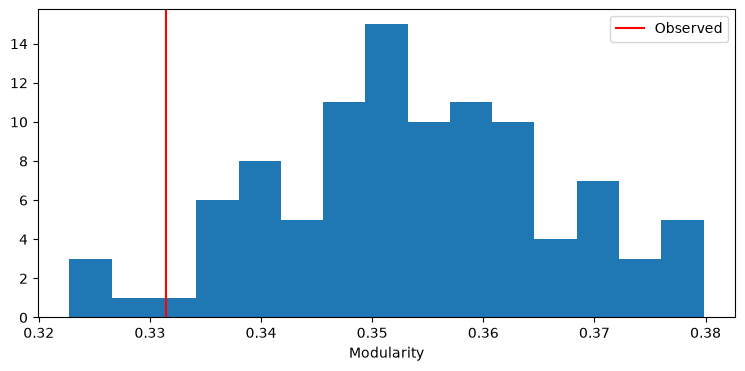

In [7]:
rng=np.random.default_rng(7202);edge_list=list(g.edges());ww=np.array([g[u][v]['weight'] for u,v in edge_list]);null=[]
for i in range(NULL_REPEATS):
 h=g.copy()
 for (u,v),vweight in zip(edge_list,rng.permutation(ww)):h[u][v]['weight']=vweight
 null.append(max(runs(h,count=NULL_SEEDS)[1]))
 if i%20==0:print('Null',i,flush=True)
obs=max(qs[:NULL_SEEDS]);pv=(1+sum(q>=obs for q in null))/(NULL_REPEATS+1)
pd.DataFrame({'null_Q':null}).to_csv(O/'null.csv',index=False)

print('Observed Q:',obs,'Permutation p:',pv)
plt.figure(figsize=(9,4));plt.hist(null,bins=15);plt.axvline(obs,color='red',label='Observed');plt.xlabel('Modularity');plt.legend();plt.show()

## 6. ตรวจ bridge และ centrality
bridge_trips ต้องเปรียบเทียบ community ของเพื่อนบ้านกับจังหวัดเป้าหมาย มี assertion ตรวจผลรวมสองด้าน คะแนน 45/35/20 เป็นคะแนนคัดกรองสมมติ **ไม่ใช้เป็น objective เลือกฐาน** ระยะ 1/weight สำหรับ betweenness ไม่ใช่ระยะถนน

In [8]:
# Correct bridge calculation uses the neighbour, not the focal node.
cid={v:i for i,c in enumerate(p) for v in c};bridge={v:sum(a['weight'] for u,a in g[v].items() if cid[u]!=cid[v]) for v in g}
assert abs(sum(bridge.values())-2*sum(a['weight'] for u,v,a in g.edges(data=True) if cid[u]!=cid[v]))<1e-6
h=g.copy()
for u,v,a in h.edges(data=True):a['distance']=1/a['weight']
bet=nx.betweenness_centrality(h,weight='distance');rank=pd.DataFrame({'province':nodes,'strength':[g.degree(v,weight='weight') for v in nodes],'betweenness':[bet[v] for v in nodes],'bridge_trips':[bridge[v] for v in nodes]})
rank['score']=sum(coef*(rank[col]-rank[col].min())/(rank[col].max()-rank[col].min()) for col,coef in [('strength',.45),('betweenness',.35),('bridge_trips',.2)])
rank.sort_values('score',ascending=False).to_csv(O/'corrected_rank.csv',index=False,encoding='utf-8-sig')

display(rank.sort_values('score',ascending=False).head(10))

,province,strength,betweenness,bridge_trips,score
8,ชลบุรี,151513.0,0.553333,41600.0,0.950564
30,พระนครศรีอยุธยา,117413.0,0.207719,55259.0,0.680078
18,นครราชสีมา,120415.0,0.226316,46002.0,0.667255
52,สมุทรปราการ,77783.0,0.160000,50971.0,0.516633
4,กำแพงเพชร,67863.0,0.188421,45056.0,0.483730
58,สุพรรณบุรี,87943.0,0.056491,45162.0,0.460321
20,นครสวรรค์,84907.0,0.060351,37239.0,0.425067
45,ลพบุรี,83693.0,0.048772,33210.0,0.399554
54,สมุทรสาคร,39100.0,0.330526,14298.0,0.376838
55,สระบุรี,64545.0,0.000000,30873.0,0.303357


## 7. Model A และ Model B
A เพิ่ม coverage รวมเมื่อกำหนด k=2 หรือ 3; B เพิ่ม floor รายกลุ่มที่ส่วนแบ่งต้นทาง ≥10% ทดลอง 30/50/70%

coverage = เที่ยวจากจังหวัดต้นทางที่มีฐานในรัศมี / เที่ยวทั้งหมดในพอร์ต นับไม่ซ้ำ ไม่ใช่รายได้หรือส่วนแบ่งตลาดจริง สถานะ infeasible คือไม่มีชุดฐานผ่านเงื่อนไข ไม่ใช่รันผิด

In [9]:
important=[i for i in range(len(p)) if w[lab==i].sum()/w.sum()>=.1]
def solve(ww,k,floor=None):
 con=[LinearConstraint(np.c_[-A,np.eye(n)],-np.inf,0),LinearConstraint(np.r_[np.ones(n),np.zeros(n)][None,:],k,k)]
 if floor is not None:
  for i in important:
   z=ww*(lab==i);con.append(LinearConstraint(np.r_[np.zeros(n),z/ z.sum()][None,:],floor,np.inf))
 result=milp(np.r_[np.zeros(n),-ww/ww.sum()],integrality=np.ones(2*n),bounds=Bounds(0,1),constraints=con,options={'mip_rel_gap':0,'time_limit':45})
 if result.status==2:return None,None
 assert result.success,result.message
 ix=np.flatnonzero(result.x[:n]>.5);return ix,A[:,ix].any(1)
models=[];groups=[];frozen={}
for k in [2,3]:
 for floor in [None,.3,.5,.7]:
  name=f'A_{k}' if floor is None else f'B_{k}_{floor}'
  ix,cv=solve(w,k,floor)
  if ix is None:models.append(dict(model=name,status='infeasible'));continue
  frozen[name]=(ix,cv,k);models.append(dict(model=name,status='optimal',sites=' / '.join(nodes[i] for i in ix),coverage=100*w[cv].sum()/w.sum()))
  for i,c in enumerate(p):
   mask=lab==i;groups.append(dict(model=name,community=i,important=i in important,members=' / '.join(sorted(c)),market_share=100*w[mask].sum()/w.sum(),coverage=100*w[mask&cv].sum()/w[mask].sum() if w[mask].sum() else None))
print('MILP done',flush=True)

models_df=pd.DataFrame(models);display(models_df)
for name,(ix,cv,k) in frozen.items():
    assert len(ix)==k
    assert np.array_equal(cv,(D.values[:,ix]<=RADIUS_KM).any(axis=1))

MILP done


,model,status,sites,coverage
0,A_2,optimal,พิษณุโลก / สระบุรี,66.424654
1,B_2_0.3,optimal,พิษณุโลก / สระบุรี,66.424654
2,B_2_0.5,infeasible,NaN,NaN
3,B_2_0.7,infeasible,NaN,NaN
4,A_3,optimal,พิษณุโลก / มหาสารคาม / สระบุรี,82.286496
5,B_3_0.3,optimal,พิษณุโลก / มหาสารคาม / สระบุรี,82.286496
6,B_3_0.5,optimal,พิจิตร / มหาสารคาม / สมุทรสาคร,80.111310
7,B_3_0.7,infeasible,NaN,NaN


## 8. ตรวจย้อนหลังด้วยฐานที่ตรึงไว้
เลือก A ใหม่ภายใต้ k เดิมเป็น benchmark ของทุกโมเดล ไม่ใช่ regret เทียบ B ที่มี constraints เหมือนกัน ใช้เดือนร่วมและ dedup sensitivity แยกกัน บางช่วงทับซ้อน จึงไม่ใช่ independent tests หรือ unseen holdout

เลข community แต่ละช่วงเทียบตรง ๆ ไม่ได้ ใช้ ARI เทียบสมาชิก

In [10]:
temporal=[];community_time=[];common=sorted(set(d.month)&set(old.month))
cases={'2025_matched':old[old.month.isin(common)],'2026_matched':d[d.month.isin(common)],'2025_matched_dedup':old[old.month.isin(common)].drop_duplicates(subset=[c for c in old.columns if c!='id'])}
cases.update({m:d[d.month==m] for m in sorted(d.month.unique())})
for name,df in cases.items():
 gg=graph(df);pp,qq=runs(gg,count=20);ll=labels(pp[int(np.argmax(qq))]);ww=weights(df)
 community_time.append(dict(period=name,ARI_to_2026=ari(lab,ll),groups=len(set(ll))))
 for model,(ix,cv,k) in frozen.items():
  _,best=solve(ww,k);temporal.append(dict(period=name,model=model,fixed_coverage=100*ww[cv].sum()/ww.sum(),unconstrained_reoptimized=100*ww[best].sum()/ww.sum(),loss_pp=100*(ww[best].sum()-ww[cv].sum())/ww.sum()))
  for i in set(ll):
   mask=ll==i;community_time.append(dict(period=name,model=model,community=i,origin_share=ww[mask].sum()/ww.sum(),coverage=ww[mask&cv].sum()/ww[mask].sum() if ww[mask].sum() else None))
frames={'resolution':validation,'models':models,'community_coverage':groups,'temporal':temporal,'temporal_communities':community_time}
for name,rr in frames.items():pd.DataFrame(rr).to_csv(O/(name+'.csv'),index=False,encoding='utf-8-sig')
quality=pd.crosstab(d['product'],d.month);quality.to_csv(O/'product_month_rows.csv',encoding='utf-8-sig')

display(pd.DataFrame(temporal).groupby('model').agg(min_coverage=('fixed_coverage','min'),max_coverage=('fixed_coverage','max'),max_loss_pp=('loss_pp','max')))
(O/'summary.json').write_text(json.dumps({'observed_Q':float(obs),'null_p':float(pv),'models':models},ensure_ascii=False,indent=2),encoding='utf8')

,min_coverage,max_coverage,max_loss_pp
model,,,
A_2,64.002687,68.443635,2.227261
A_3,79.935752,83.572290,0.192291
B_2_0.3,64.002687,68.443635,2.227261
B_3_0.3,79.935752,83.572290,0.192291
B_3_0.5,76.856051,83.764580,3.860186


1013

## 9. กราฟผลจริงและ Network ที่อ่านง่าย
กราฟ Network แสดงจังหวัดทั้งหมด สีคือกลุ่มที่รันได้จริง ขนาดจุดคือ strength ดาวคือฐาน A สามฐาน จัดกลุ่มแยกเพื่ออ่าน ไม่ใช่แผนที่หรือหลักฐานว่ากลุ่มแยกขาด

ชื่อไทยต้องมีฟอนต์ไทยในเครื่อง เซลล์เลือก Tahoma/Noto Sans Thai/Th Sarabun หากไม่มีจะแสดงรหัสจังหวัด พร้อมตารางรหัสประกอบ เพื่อไม่ให้ชื่อเป็นสี่เหลี่ยม

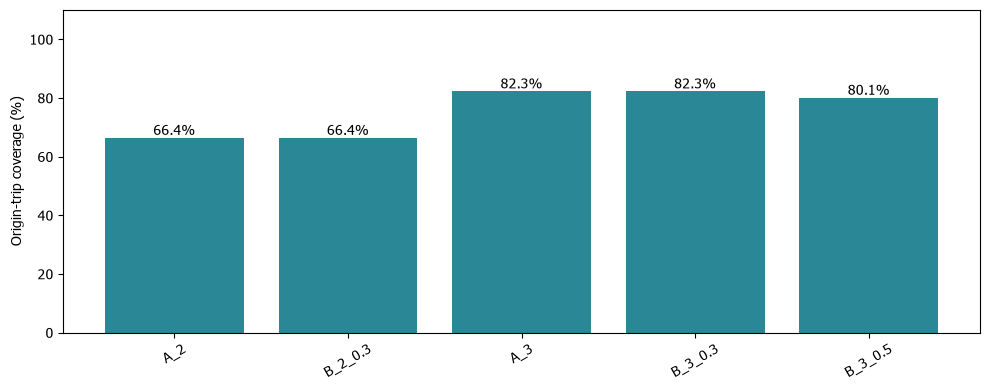

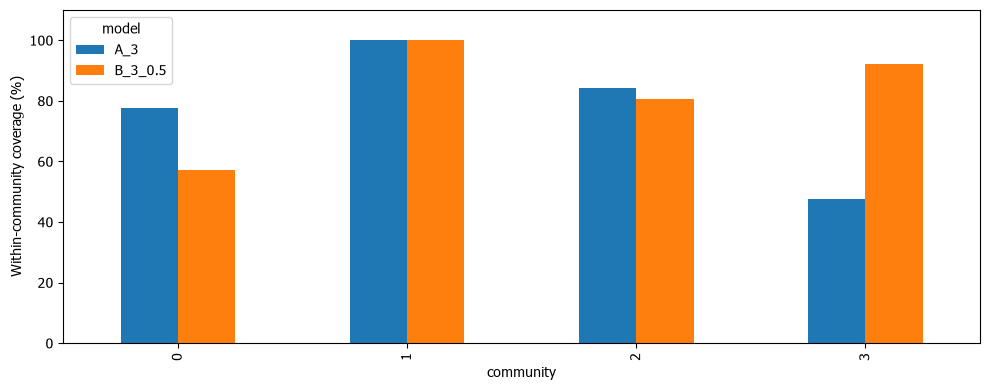

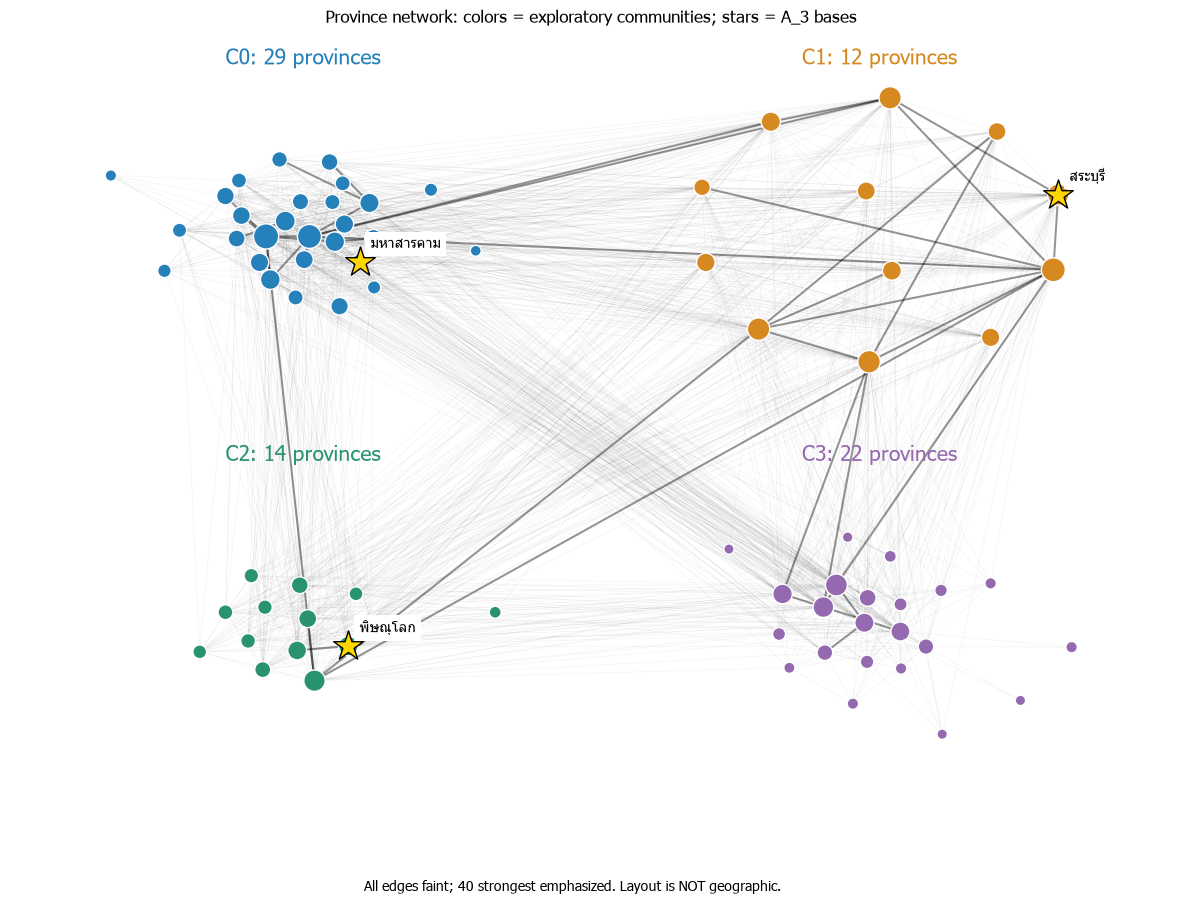

,base,code
0,พิษณุโลก,P36
1,มหาสารคาม,P38
2,สระบุรี,P56


In [11]:
from matplotlib import font_manager
available={f.name for f in font_manager.fontManager.ttflist}
thai_font=next((f for f in ['Tahoma','Noto Sans Thai','TH Sarabun New'] if f in available),None)
if thai_font: plt.rcParams['font.family']=thai_font
node_codes={v:f'P{i+1:02d}' for i,v in enumerate(nodes)}
pd.DataFrame({'code':list(node_codes.values()),'province':nodes}).to_csv(O/'province_codes.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(10,4))
valid=models_df[models_df.status=='optimal']; bars=ax.bar(valid.model,valid.coverage,color='#298796');ax.bar_label(bars,fmt='%.1f%%');ax.set_ylim(0,110);ax.set_ylabel('Origin-trip coverage (%)');plt.xticks(rotation=30);plt.tight_layout();plt.savefig(O/'coverage.png',dpi=160);plt.show()

groups_df=pd.DataFrame(groups)
comparison=groups_df[groups_df.model.isin(['A_3','B_3_0.5'])].pivot(index='community',columns='model',values='coverage')
comparison.plot.bar(figsize=(10,4),ylim=(0,110),ylabel='Within-community coverage (%)');plt.tight_layout();plt.savefig(O/'community_coverage.png',dpi=160);plt.show()

from matplotlib.colors import ListedColormap
palette=ListedColormap(['#2680B9','#D58920','#29936F','#9469B0']);positions={}; m=len(p)
for i,group in enumerate(p):
    center=np.array([3*(i%2),-3*(i//2)])
    sub=g.subgraph(sorted(group)).copy()
    local=nx.spring_layout(sub,seed=7202,weight=None,iterations=300)
    for v,xy in local.items():positions[v]=center+xy
strength=dict(g.degree(weight='weight'));mx=max(strength.values());base_names={nodes[i] for i in frozen['A_3'][0]}
top=sorted(g.edges(),key=lambda e:g[e[0]][e[1]]['weight'],reverse=True)[:40]
fig,ax=plt.subplots(figsize=(15,10))
nx.draw_networkx_edges(g,positions,ax=ax,alpha=.06,width=.4)
nx.draw_networkx_edges(g,positions,edgelist=top,ax=ax,alpha=.4,width=1.5)
nx.draw_networkx_nodes(g,positions,ax=ax,node_color=[palette(cid[v]%4) for v in g],node_size=[50+280*np.sqrt(strength[v]/mx) for v in g],edgecolors='white')
for v in base_names:
    ax.scatter(*positions[v],s=500,marker='*',c='gold',edgecolors='black',zorder=5)
    ax.annotate(v if thai_font else node_codes[v],positions[v],xytext=(8,10),textcoords='offset points',bbox=dict(fc='white',ec='none'),zorder=6)
ax.set_title('Province network: colors = exploratory communities; stars = A_3 bases')
for i,group in enumerate(p):
    ax.text(3*(i%2),-3*(i//2)+1.25,f'C{i}: {len(group)} provinces',ha='center',color=palette(i%4),fontsize=15)
ax.axis('off');fig.text(.5,.02,'All edges faint; 40 strongest emphasized. Layout is NOT geographic.',ha='center');plt.savefig(O/'network.png',dpi=170,bbox_inches='tight');plt.show()
display(pd.DataFrame({'base':sorted(base_names),'code':[node_codes[v] for v in sorted(base_names)]}))

## 9.1 เครือข่ายบนพิกัดจังหวัด: กลุ่มตลาดและฐาน Model A
เพิ่มสองภาพจากข้อมูลและผลเดิม:
1. **Market groups** ไม่มีดาว เพื่ออ่านกลุ่มเชิงสำรวจบนพิกัดจังหวัด
2. **Model A bases** ดาวเป็นฐาน A สามฐาน จุดจางคือต้นทางที่ไม่อยู่ในรัศมีบริการตาม distance matrix

ขนาดจุดในสองภาพนี้ = เที่ยวต้นทาง (ต่างจากกราฟ Network ก่อนหน้าที่ใช้ strength)
สี = community เชิงสำรวจ ยังไม่ใช่เขตตลาดที่ยืนยันแล้ว แสดงเฉพาะ 60 เส้นที่มีเที่ยวรวมสองทิศทางมากที่สุด

วงรัศมีที่วาดเป็น **ellipse approximation** ของระยะ 150 กม. บนพิกัดละติจูด/ลองจิจูด คำนวณ coverage จาก Haversine ใน distance matrix เดิม ไม่ได้ใช้ ellipse ตัดสินว่าครอบคลุมหรือไม่ ภาพเป็นเครือข่ายบนพิกัด ไม่ได้มีเส้นเขตประเทศไทย และไม่ได้แสดงระยะถนนจริง

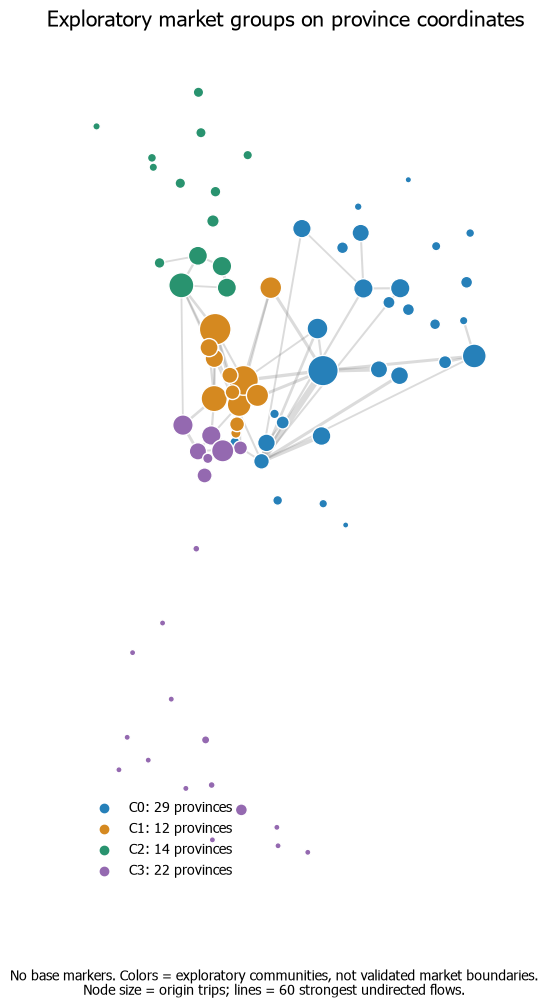

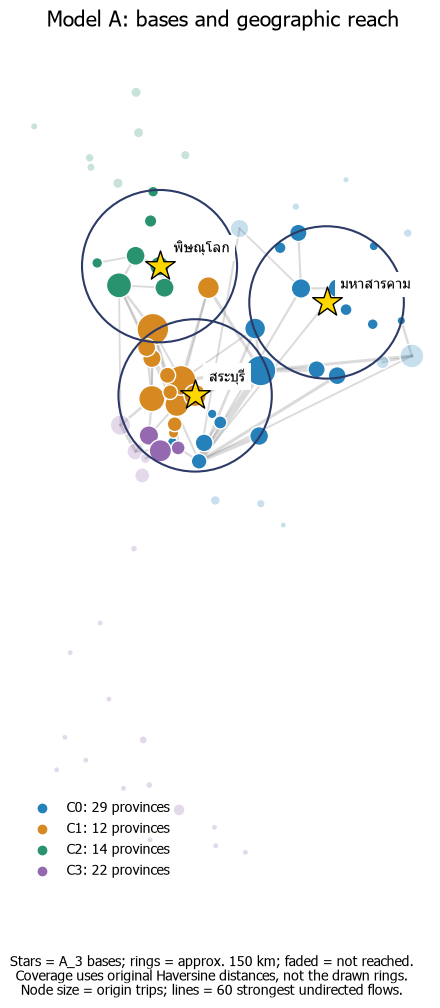

In [12]:
from matplotlib.patches import Ellipse
from matplotlib.colors import ListedColormap
palette = ListedColormap(['#2680B9','#D58920','#29936F','#9469B0']) if len(p)<=4 else plt.get_cmap('tab20',len(p))
# Reindex explicitly: coordinates must match the node order used by the MILP.
map_coords=coords.loc[nodes]
x=map_coords.LNG.to_numpy(); y=map_coords.LAT.to_numpy()
index_by_node={v:i for i,v in enumerate(nodes)}
top=sorted(g.edges(),key=lambda e:g[e[0]][e[1]]['weight'],reverse=True)[:60]
wmax=max((g[u][v]['weight'] for u,v in top),default=1)
ix_A3,cv_A3,_=frozen['A_3']
assert abs(100*w[cv_A3].sum()/w.sum()-models_df.set_index('model').loc['A_3','coverage'])<1e-9

def thai_map(path,bases):
    fig,ax=plt.subplots(figsize=(9,11))
    for u,v in top:
        i,j=index_by_node[u],index_by_node[v]
        ax.plot([x[i],x[j]],[y[i],y[j]],color='grey',alpha=.28,
                lw=.5+4*g[u][v]['weight']/wmax,zorder=1)
    colors=np.array([palette(cid[v]) for v in nodes])
    colors[:,3]=[1 if (not bases or cv_A3[i]) else .25 for i in range(n)]
    ax.scatter(x,y,s=20+500*w/w.max(),c=colors,edgecolors='white',zorder=2)
    if bases:
        r=RADIUS_KM/111
        for i in ix_A3:
            ax.add_patch(Ellipse((x[i],y[i]),2*r/np.cos(np.radians(y[i])),2*r,
                               fill=False,ec='#2B3A67',lw=1.5,zorder=3))
            ax.scatter(x[i],y[i],s=500,marker='*',c='gold',edgecolors='black',zorder=5)
            ax.annotate(nodes[i] if thai_font else node_codes[nodes[i]],(x[i],y[i]),
                        xytext=(10,10),textcoords='offset points',
                        bbox=dict(fc='white',ec='none'),zorder=6)
    for i in range(len(p)):
        ax.scatter([],[],color=palette(i),label=f'C{i}: {len(p[i])} provinces')
    ax.legend(frameon=False,loc='lower left')
    ax.set_aspect(1/np.cos(np.radians(13)));ax.axis('off')
    ax.set_title('Model A: bases and geographic reach' if bases else 'Exploratory market groups on province coordinates',fontsize=15,pad=20)
    caption=f'Stars = A_3 bases; rings = approx. {RADIUS_KM} km; faded = not reached.\nCoverage uses original Haversine distances, not the drawn rings.' if bases else 'No base markers. Colors = exploratory communities, not validated market boundaries.'
    fig.text(.5,.025,caption+'\nNode size = origin trips; lines = 60 strongest undirected flows.',ha='center',fontsize=10)
    fig.subplots_adjust(bottom=.12)
    plt.savefig(path,dpi=160,bbox_inches='tight');plt.show()

thai_map(O/'map_groups.png',bases=False)
thai_map(O/'map_bases.png',bases=True)


## 10. อ่านผลก่อนเขียนข้อสรุป
- ใช้ตารางผลปัจจุบัน ไม่คัดตัวเลขรายงานเดิมหากไม่ตรง
- A เป็นกรณีฐานด้าน coverage ไม่ได้ยืนยันผลตอบแทนลงทุน
- B เปิดให้เห็นข้อแลกเปลี่ยนรายกลุ่ม ไม่จำเป็นต้องชนะ A; หาก null ไม่ผ่าน ต้องระบุ exploratory
- เพิ่มฐานอาจเพิ่ม coverage แต่ยังไม่มีต้นทุน กำลังรถ ลูกค้าจริง และคู่แข่ง
- ก่อนส่ง: ตรวจสิทธิ์ต้นทาง completeness สินค้า–เดือน ระยะถนน พอร์ตธุรกิจ และแพ็กสภาพแวดล้อม
- AI ช่วยสร้างโค้ด/คำอธิบาย ทีมต้องตรวจสมมติฐานและผล ไม่ใช้ AI เป็นแหล่งข้อเท็จจริงตลาด

### เชื่อม Rubric
Problem framing: คำถามการเลือกชุดฐาน; Data/Graph: audit และกฎสินค้า; Rigor: seeds/null/temporal; Technology/AI: โค้ดที่รันซ้ำและบันทึกเวอร์ชัน; Business: trade-off และข้อจำกัด

**ข้อจำกัดเพิ่มเติม:** ยังไม่รัน B ทุก resolution, ยังไม่ทดสอบหลาย null families, ยังไม่หาจำนวนฐานต่ำสุดภายใต้ coverage target และไม่ได้แก้ปัญหา robust optimization แบบ worst-case